# Assignment 5: Autoencoders
Date: 

Report produced by:  
COMP 3705 Group 3

## Data Preprocessing

### Data Loading

In [2]:
import pandas as pd
import numpy as np
import math as m
import tensorflow as tf
from sklearn.model_selection import train_test_split as tts
from keras.models import Model, Sequential
from keras.layers import Input, Dense
import matplotlib.pyplot as plt
# Set TensorFlow deprication warnings to False
import tensorflow.python.util.deprecation as deprecation
deprecation._PRINT_DEPRECATION_WARNINGS = False

# Load the Dataset and Check Shape
df = pd.read_csv("csvImages 10k x 784.csv")
df_clean = df.copy()
print("Data Shape:", df_clean.shape)

Using TensorFlow backend.


Data Shape: (9999, 784)


### Check Data Integrity

In [3]:
print("Number of Duplicate Rows:",df_clean.duplicated().sum())
print("Min value across all columns:",df_clean.min().min())
print("Max value across all columns:",df_clean.max().max())
print("Number of missing values in data:",df_clean.isna().sum().sum())

Number of Duplicate Rows: 1
Min value across all columns: 0
Max value across all columns: 255
Number of missing values in data: 0


As the data across all columns ranges between 0 and 255, we can determine that there are no unexpected RGB values.  
Additionally, since there are also no missing values anywhere in the data we can proceed with the dataset as-is.

In [4]:
df_clean = df_clean.drop_duplicates()
print("Cleaned Data Shape:", df_clean.shape)

Cleaned Data Shape: (9998, 784)


### Reshape for Visualizations

In [5]:
# Convert DataFrame to Numpy Array and Normalize Values
img_data = df_clean.values/255
img_data = img_data.reshape((-1,28,28))
print("Shape of Array:",img_data.shape)
print("Shape of Each Row:",img_data[0].shape)

Shape of Array: (9998, 28, 28)
Shape of Each Row: (28, 28)


After checking the data, we converted the DataFrame into a NumPy array and normalized the pixel values by dividing them by 255. This changed the value range from 0–255 to  0–1. Normalization was done to helps the neural network train more effectively by ensuring no one pixel disproportionately influences the model.  
Next, we reshaped each image from 784 values into a 28 × 28 image. We did this because each row contains 784 points, each pertaining to a pixel in a 28x28 image. Reshaping the data allows us to display the images using Matplotlib before training the autoencoder.

### Pre-Encoding Visualizations

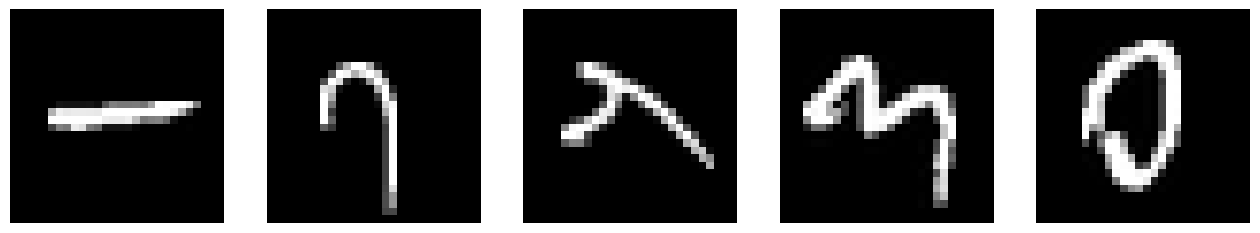

In [6]:
plt.figure(figsize=(16,10))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(img_data[i],cmap="gray")
    plt.axis("off")

We plotted the first five images using using a grayscale colormap. These original images serve as the baseline we will compare the decoded images against when judging the autoencoder.  
Each image shows a light digit stroke on a dark background, roughly centred in the frame. Most pixels, especially around the edges, are 0 (black) and carry no information about the digit.  
Much of each image is "empty" space, which suggests the images can be compressed substantially without losing the digit itself.

### Reshape for Data Encoding

In [7]:
img_data = img_data.reshape((-1,28**2))
print("Shape of Array:",img_data.shape)
print("Shape of Each Row:",img_data[0].shape)

Shape of Array: (9998, 784)
Shape of Each Row: (784,)


We flattened each 28×28 image back into a one-dimensional array of 784 values. Keras `Dense` layers take one-dimensional input, so the autoencoder's input layer expects 784 values per image.  
The data shape is back to **(9998, 784)**, with values between 0 and 1, which is ready to feed into the network. 

In [8]:
# Dummy Cell - Used for Run All Above - Remove Before Submission

## Model Selection

In [1]:
def compile_autoencoder(data,autoencoder,weights,validation=None,optimizer="adadelta",loss="binary_crossentropy",epochs=50):
    autoencoder["decoded"].set_weights(weights)
    autoencoder["decoded"].compile(optimizer=optimizer,loss=loss)
    autoencoder["decoded"].fit(data,data,validation_data=validation,epochs=epochs)

def create_autoencoder(data,activation_function="relu",activation_final="sigmoid",loss_function="binary_crossentropy",optimizer="adadelta",epochs=50):
    autoencoder = dict()
    i = 0
    train_data, test_data = tts(data,train_size=0.9,test_size=0.1,random_state=42)
    # Define Input Layer
    input_layer = Input(shape=(784,))
    # Define Encoding Layers
    hidden_encoding1 = Dense(784,activation=act)(input_layer)
    hidden_encoding2 = Dense(512,activation=act)(hidden_encoding1)
    hidden_encoding3 = Dense(256,activation=act)(hidden_encoding2)
    hidden_encoding4 = Dense(128,activation=act)(hidden_encoding3)
    # Final Encoding Layer
    encoding_stage = Dense(64,activation=act)(hidden_encoding4)
    # Define Decoding Layers
    hidden_decoding1 = Dense(128,activation=act)(encoding_stage)
    hidden_decoding2 = Dense(256,activation=act)(hidden_decoding1)
    hidden_decoding3 = Dense(512,activation=act)(hidden_decoding2)
    hidden_decoding4 = Dense(784,activation=act)(hidden_decoding3)
    # Final Decoding Layer
    decoding_stage = Dense(784,activation=act_fnl)(hidden_decoding4)
    # Define Autoencoder Model
    autoencoder[i] = {"encoded": Model(input_layer,encoding_stage),
                    "decoded": Model(input_layer,decoding_stage),
                    "Final Act": act_fnl,
                    "Hidden Act": act,
                    "Loss Function": loss,
                    "Optimizer": opti,
    }
    # Set Starting Weights
    if i == 0:
        initial_weights = autoencoder[0]["decoded"].get_weights()
    # Compile and Train Model
    compile_autoencoder(train_data,autoencoder[i],initial_weights,optimizer=opti,loss=loss,epochs=epochs)
    autoencoder[i]["Loss"] = autoencoder[i]["decoded"].evaluate(test_data,test_data,verbose=0)
    i += 1
    return autoencoder

In [12]:
activation_function = ["relu","sigmoid"]
activation_final = ["sigmoid","softmax"]
loss_functions = ["binary_crossentropy","mean_squared_error","mean_absolute_error"]
optimizers = ["adadelta","adagrad","adam"]
i = 0
for act in activation_function:
    for act_fnl in activation_final:
        for loss in loss_functions:
            for opti in optimizers:
                if i == 0:
                    autoencoders1 = create_autoencoder(img_data,act_fnl,act,loss,opti,100)
                    i += 1
df_encoded_pars1 = pd.DataFrame(autoencoders1).transpose().drop(columns=["decoded","encoded"])
df_encoded_pars1

Epoch 1/100
8998/8998 [==============================] - 25s 3ms/step - loss: 0.2960
Epoch 2/100
8998/8998 [==============================] - 20s 2ms/step - loss: 0.2292
Epoch 3/100
8998/8998 [==============================] - 20s 2ms/step - loss: 0.2204
Epoch 4/100
8998/8998 [==============================] - 20s 2ms/step - loss: 0.2062
Epoch 5/100
8998/8998 [==============================] - 19s 2ms/step - loss: 0.2012
Epoch 6/100
8998/8998 [==============================] - 19s 2ms/step - loss: 0.1916
Epoch 7/100
8998/8998 [==============================] - 19s 2ms/step - loss: 0.1759
Epoch 8/100
8998/8998 [==============================] - 18s 2ms/step - loss: 0.1665
Epoch 9/100
8998/8998 [==============================] - 18s 2ms/step - loss: 0.1569
Epoch 10/100
8998/8998 [==============================] - 19s 2ms/step - loss: 0.1484
Epoch 11/100
8998/8998 [==============================] - 19s 2ms/step - loss: 0.1418
Epoch 12/100
8998/8998 [==============================] - 19s 2

,Final Act,Hidden Act,Loss,Loss Function,Optimizer
0,sigmoid,relu,0.0952807,binary_crossentropy,adadelta


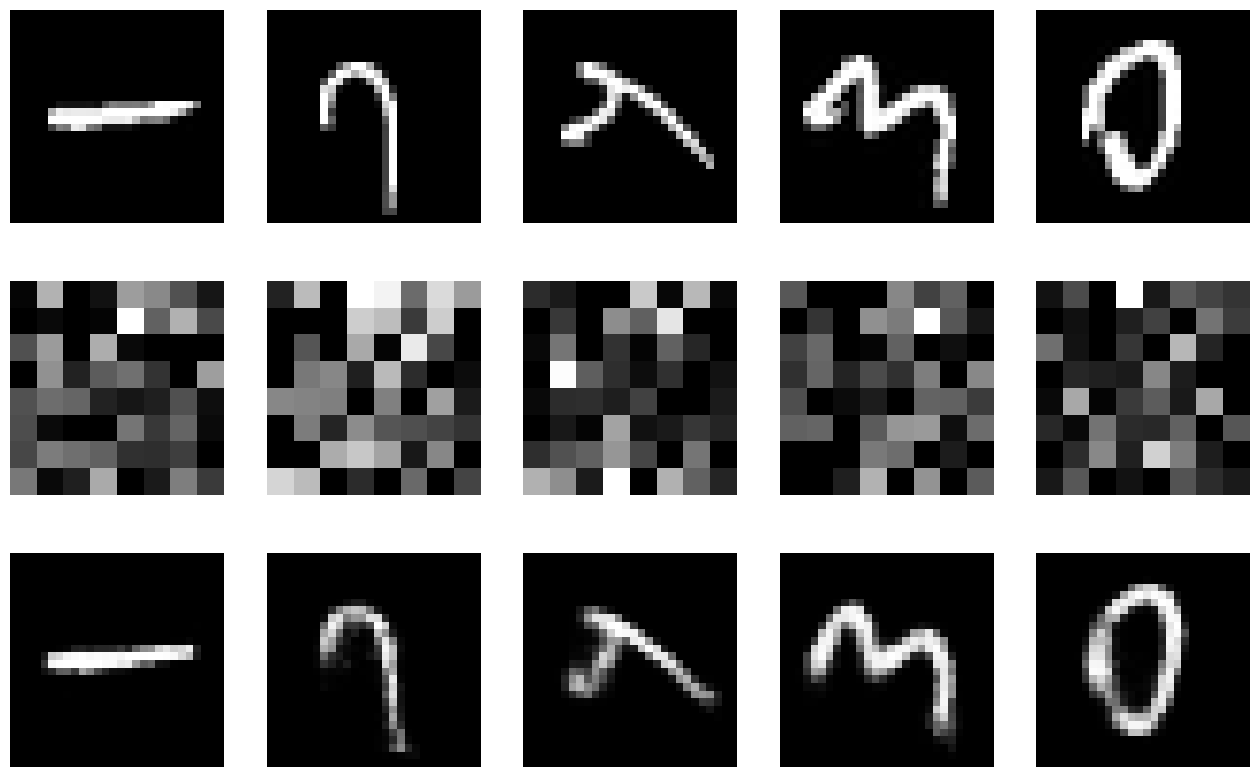

In [13]:
def plot_images(data, autoencoders,num_img=5):
    data = data.reshape((-1,28**2))
    for i in range(len(autoencoders)):
        encoded_img = autoencoders[i]["encoded"].predict(data[:num_img]).reshape((-1,8,8))
        decoded_img = autoencoders[i]["decoded"].predict(data[:num_img]).reshape((-1,28,28))
        loss = autoencoders[i]["Loss Function"]
        hidden_act = autoencoders[i]["Hidden Act"]
        final_act = autoencoders[i]["Final Act"]
        data = data.reshape((-1,28,28))
        # print("Autoencoder ID:",i)
        plt.figure(figsize=(16,10))
        for j in range(num_img):
            plt.subplot(3,num_img,j+1)
            plt.imshow(data[j],cmap="gray")
            plt.axis("off")

            plt.subplot(3,num_img,j+1+num_img)
            plt.imshow(encoded_img[j],cmap="gray")
            plt.axis("off")

            plt.subplot(3,num_img,j+1+num_img*2)
            plt.imshow(decoded_img[j],cmap="gray")
            plt.axis("off")
        data = data.reshape((-1,28**2))
plot_images(img_data,autoencoders1)

In [167]:
df_encoded_pars1 = pd.DataFrame(autoencoders).transpose().drop(columns=["decoded","encoded"])
df_encoded_pars1

,Final Act,Hidden Act,loss
0,sigmoid,relu,binary_crossentropy
1,sigmoid,relu,mean_squared_error
2,sigmoid,relu,mean_absolute_error
3,softmax,relu,binary_crossentropy
4,softmax,relu,mean_squared_error
5,softmax,relu,mean_absolute_error
6,sigmoid,sigmoid,binary_crossentropy
7,sigmoid,sigmoid,mean_squared_error
8,sigmoid,sigmoid,mean_absolute_error
9,softmax,sigmoid,binary_crossentropy


For the initial set of hyperparameter, we tested the differences that occured from changing the hidden layers activation function, the final activation function, and the loss function. These were tested with ***Adadelta*** set as the optimizer. Now that we've narrowed down our model selection to 3 sets of hyperparameters that resulted in viable image reconstructns, we will be testing different optimizers to determine the best possible results.

In [ ]:
activation_function = ["relu"]
activation_final = ["sigmoid","softmax"]
loss_functions = ["binary_crossentropy","mean_squared_error"]
optimizers = ["adam","adagrad"]
autoencoders2 = create_autoencoder(img_data,activation_function,activation_final,loss_functions,optimizers)
df_encoded_pars2 = pd.DataFrame(autoencoders2).transpose().drop(columns=["decoded","encoded"])

Epoch 1/50
8998/8998 [==============================] - 14s 2ms/step - loss: 0.2222
Epoch 2/50
8998/8998 [==============================] - 10s 1ms/step - loss: 0.1549
Epoch 3/50
8998/8998 [==============================] - 11s 1ms/step - loss: 0.1307
Epoch 4/50
8998/8998 [==============================] - 10s 1ms/step - loss: 0.1190
Epoch 5/50
8998/8998 [==============================] - 10s 1ms/step - loss: 0.1123
Epoch 6/50
8998/8998 [==============================] - 10s 1ms/step - loss: 0.1075
Epoch 7/50
8998/8998 [==============================] - 10s 1ms/step - loss: 0.1047
Epoch 8/50
8998/8998 [==============================] - 9s 1ms/step - loss: 0.1024
Epoch 9/50
8998/8998 [==============================] - 10s 1ms/step - loss: 0.1000
Epoch 10/50
8998/8998 [==============================] - 10s 1ms/step - loss: 0.0975
Epoch 11/50
8998/8998 [==============================] - 10s 1ms/step - loss: 0.0968
Epoch 12/50
8998/8998 [==============================] - 10s 1ms/step - los

### Final Selection

## Conclusion

### Image Visualizations

## Final Propositions


## Acknowledgement of Contributions
### Group 3 Members:  
Sebastian Levy  
Idongesit Orok  
Miracle Okojie  

### Task Distribution:  

Load and Check Data - Sebastian Levy  
Normalize Data and Visualizations - Sebastian Levy  
Prepare Data for Encoding - Sebastian Levy  
Data Observations and Analysis - Sebastian Levy, Idongesit Orok, Miracle Okojie  


We, Group 3, acknowledge that we understand all parts of this assignment, including those which we did not personally carry out.